# Clasificación: Comparación de Modelos

### Imports y Configuración

In [1]:
import sys
sys.path.append("/workspace/src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from EstiloGraficos import aplicar_estilo

# Misma paleta y estilo que el dashboard (components/plotly_theme.py)
aplicar_estilo()

# Textos largos completos en las tablas (criterio de selección, hiperparámetros)
pd.set_option("display.max_colwidth", None)

from Modelado import (
    SEED, UMBRAL, RECALL_MINIMO, USAR_GPU, GPU_DISPOSITIVOS, PREDICTORES,
    NOMBRES_CLF, NOMBRES_FASE2, CLAVE_BENCHMARK, ESTRATEGIAS,
    cargar_split, separar_x_y, crear_cv, resumen_dispositivos,
    cargar_ganador_fase1, crear_benchmark, cargar_cv_fase1, formatear_tabla_cv, elegir_mejor,
    evaluar_test_modelos, graficar_curvas_test, intervalos_bootstrap, graficar_intervalos_bootstrap,
    formatear_hiperparametros, probabilidades_oof, elegir_umbrales, graficar_umbral, metricas_con_umbral, graficar_matrices,
    guardar_final, cargar_modelo_final,
)

In [2]:
resumen_dispositivos().style.set_caption(f"USAR_GPU = {USAR_GPU}")

,Dispositivo
Modelo,
Logística,CPU
Logística Ridge (L2),CPU
Logística Lasso (L1),CPU
KNN,CPU
SVC (RBF),CPU
Random Forest,CPU
XGBoost,CPU
LightGBM,CPU
CatBoost,CPU


### Datos: Split y Folds

In [3]:
df = pd.read_csv('/workspace/data/raw/screen_time_mental_health.csv')

df_train, df_test = cargar_split(df)
X_train, y_train = separar_x_y(df_train)
X_test, y_test = separar_x_y(df_test)
cv = crear_cv(SEED)

pd.DataFrame({
    "Filas": [len(X_train), len(X_test)],
    "Predictores": [X_train.shape[1], X_test.shape[1]],
    "Deprimidos": [int(y_train.sum()), int(y_test.sum())],
    "Prevalencia": [round(y_train.mean(), 3), round(y_test.mean(), 3)],
}, index=pd.Index(["Train", "Test"], name="Conjunto"))

,Filas,Predictores,Deprimidos,Prevalencia
Conjunto,,,,
Train,3848,6,630,0.164
Test,962,6,157,0.163


## Comparación de Modelos

Se carga el Pipeline ganador de cada modelo (ya reentrenado con todo el train) y su `ganador.json`. Se agrega la **logística benchmark original** (`LogisticRegression(class_weight="balanced", max_iter=1000)`, sin tuning) como modelo de referencia fijo. Se entrena aquí con el train, porque no tiene hiperparámetros, y solo se usa en el test.

In [4]:
pipelines, ganadores = {}, {}
for clave in NOMBRES_CLF:
    pipelines[clave], ganadores[clave] = cargar_ganador_fase1(clave)

# Modelo de referencia fijo
pipelines = {CLAVE_BENCHMARK: crear_benchmark(SEED).fit(X_train, y_train), **pipelines}

pd.DataFrame({
    "Estrategia": [ESTRATEGIAS[g["estrategia"]] for g in ganadores.values()],
    "PR-AUC fase 1": [f"{g['pr_auc_media']:.3f} ± {g['pr_auc_de']:.3f}" for g in ganadores.values()],
    "Hiperparámetros": [formatear_hiperparametros(g["hiperparametros"]) for g in ganadores.values()],
    "Dispositivo": [g["dispositivo_entrenamiento"] for g in ganadores.values()],
}, index=pd.Index([NOMBRES_CLF[c] for c in ganadores], name="Modelo"))

,Estrategia,PR-AUC fase 1,Hiperparámetros,Dispositivo
Modelo,,,,
Logística,Pesos de clase,0.393 ± 0.043,sin tuning,CPU
Logística Ridge (L2),Pesos de clase,0.394 ± 0.044,C=0.07459,CPU
Logística Lasso (L1),Pesos de clase,0.394 ± 0.044,C=0.07459,CPU
KNN,Nativo (sin balanceo),0.391 ± 0.045,"n_neighbors=285, p=1, weights=distance",CPU
SVC (RBF),Pesos de clase,0.393 ± 0.048,"C=2.796, gamma=0.00105",CPU
Random Forest,Nativo (sin balanceo),0.398 ± 0.056,"max_depth=5, max_features=0.5, min_samples_leaf=5, n_estimators=601",CPU
XGBoost,SMOTENC,0.393 ± 0.050,"colsample_bytree=0.7434, learning_rate=0.01415, max_depth=2, min_child_weight=8, n_estimators=367, subsample=0.7324",CPU
LightGBM,Nativo (sin balanceo),0.396 ± 0.052,"colsample_bytree=0.9443, learning_rate=0.01021, max_depth=7, min_child_samples=36, n_estimators=236, num_leaves=8, subsample=0.877",CPU
CatBoost,Nativo (sin balanceo),0.406 ± 0.053,"depth=4, iterations=232, l2_leaf_reg=1.572, learning_rate=0.02539",CPU


In [5]:
# Logística benchmark: CV del EDA (EDA.ipynb, todo el dataset). No comparable con la CV del train.
CV_BENCHMARK_EDA = {
    "PR-AUC media": 0.399, "PR-AUC DE": 0.011,
    "ROC-AUC media": 0.766, "ROC-AUC DE": 0.007,
    "Precision media": 0.320, "Precision DE": 0.013,
    "Recall media": 0.666, "Recall DE": 0.035,
    "F1 media": 0.432, "F1 DE": 0.019,
    "Accuracy media": 0.714, "Accuracy DE": 0.009,
}

tabla_cv = cargar_cv_fase1(ganadores, CV_BENCHMARK_EDA)
formatear_tabla_cv(tabla_cv).rename(index=NOMBRES_FASE2)

,PR-AUC,ROC-AUC,Precision,Recall,F1,Accuracy,Δ PR-AUC vs benchmark
Modelo,,,,,,,
CatBoost,0.406 ± 0.053,0.751 ± 0.030,0.590 ± 0.118,0.132 ± 0.015,0.214 ± 0.022,0.842 ± 0.006,0.007
Logística benchmark,0.399 ± 0.011,0.766 ± 0.007,0.320 ± 0.013,0.666 ± 0.035,0.432 ± 0.019,0.714 ± 0.009,0.000
Random Forest,0.398 ± 0.056,0.747 ± 0.033,0.599 ± 0.080,0.113 ± 0.006,0.189 ± 0.008,0.842 ± 0.004,-0.001
LightGBM,0.396 ± 0.052,0.748 ± 0.032,0.630 ± 0.126,0.075 ± 0.011,0.133 ± 0.018,0.841 ± 0.004,-0.003
Logística Lasso (L1),0.394 ± 0.044,0.756 ± 0.031,0.312 ± 0.030,0.659 ± 0.052,0.423 ± 0.038,0.705 ± 0.023,-0.005
Logística Ridge (L2),0.394 ± 0.044,0.756 ± 0.031,0.312 ± 0.031,0.648 ± 0.048,0.421 ± 0.038,0.708 ± 0.025,-0.005
XGBoost,0.393 ± 0.050,0.747 ± 0.028,0.333 ± 0.038,0.563 ± 0.045,0.418 ± 0.042,0.742 ± 0.024,-0.006
Logística,0.393 ± 0.043,0.756 ± 0.030,0.309 ± 0.032,0.652 ± 0.053,0.420 ± 0.040,0.704 ± 0.026,-0.006
SVC (RBF),0.393 ± 0.048,0.754 ± 0.034,0.560 ± 0.052,0.137 ± 0.029,0.217 ± 0.039,0.840 ± 0.004,-0.006


### Selección del Mejor Modelo

Entre los 9 ganadores se elige el de **mayor PR-AUC media de CV**.

La logística benchmark no compite: es la referencia contra la que se mide la ganancia.

In [6]:
clave_mejor, explicacion = elegir_mejor(tabla_cv.drop(index=CLAVE_BENCHMARK))

pd.Series({
    "Modelo elegido": NOMBRES_CLF[clave_mejor],
    "Estrategia": ESTRATEGIAS[ganadores[clave_mejor]["estrategia"]],
    "PR-AUC de CV": f"{tabla_cv.loc[clave_mejor, 'PR-AUC media']:.4f} ± {tabla_cv.loc[clave_mejor, 'PR-AUC DE']:.4f}",
    "Δ PR-AUC de CV vs benchmark": f"{tabla_cv.loc[clave_mejor, 'Δ PR-AUC vs benchmark']:+.4f}",
    "Criterio": explicacion,
}, name="Selección").to_frame()

,Selección
Modelo elegido,CatBoost
Estrategia,Nativo (sin balanceo)
PR-AUC de CV,0.4057 ± 0.0530
Δ PR-AUC de CV vs benchmark,+0.0067
Criterio,Se elige 'catboost': tiene la mayor PR-AUC media de CV (0.4057 ± 0.0530).


### Test

Los 10 modelos (9 ganadores + benchmark), ya entrenados con todo el train, se evalúan **una única vez** en el test. Las métricas de clase usan el umbral 0.5, con la misma advertencia de comparabilidad de la sección anterior.

In [7]:
probas_test = {clave: pipeline.predict_proba(X_test)[:, 1] for clave, pipeline in pipelines.items()}

tabla_test = evaluar_test_modelos(probas_test, y_test, umbral=UMBRAL)
tabla_test.rename(index=NOMBRES_FASE2).round(3)

,PR-AUC,ROC-AUC,Precision,Recall,F1,Accuracy,Δ PR-AUC vs benchmark
Modelo,,,,,,,
Random Forest,0.428,0.795,0.607,0.108,0.184,0.843,0.011
KNN,0.420,0.801,0.000,0.000,0.000,0.837,0.003
Logística Lasso (L1),0.420,0.803,0.338,0.758,0.468,0.718,0.002
SVC (RBF),0.420,0.804,0.591,0.166,0.259,0.845,0.002
Logística Ridge (L2),0.419,0.802,0.340,0.764,0.471,0.719,0.001
CatBoost,0.418,0.799,0.553,0.134,0.215,0.841,0.000
Logística,0.417,0.801,0.335,0.764,0.466,0.714,0.000
Logística benchmark,0.417,0.801,0.335,0.764,0.466,0.714,0.000
LightGBM,0.416,0.800,0.556,0.064,0.114,0.839,-0.001


**Curvas ROC y Precision-Recall**

Curvas de los 10 modelos en el test. La logística benchmark aparece resaltada (línea gruesa en color tinta); las logísticas van con línea discontinua, KNN y SVC con trazo y punto, y los modelos de árboles con línea continua o punteada.

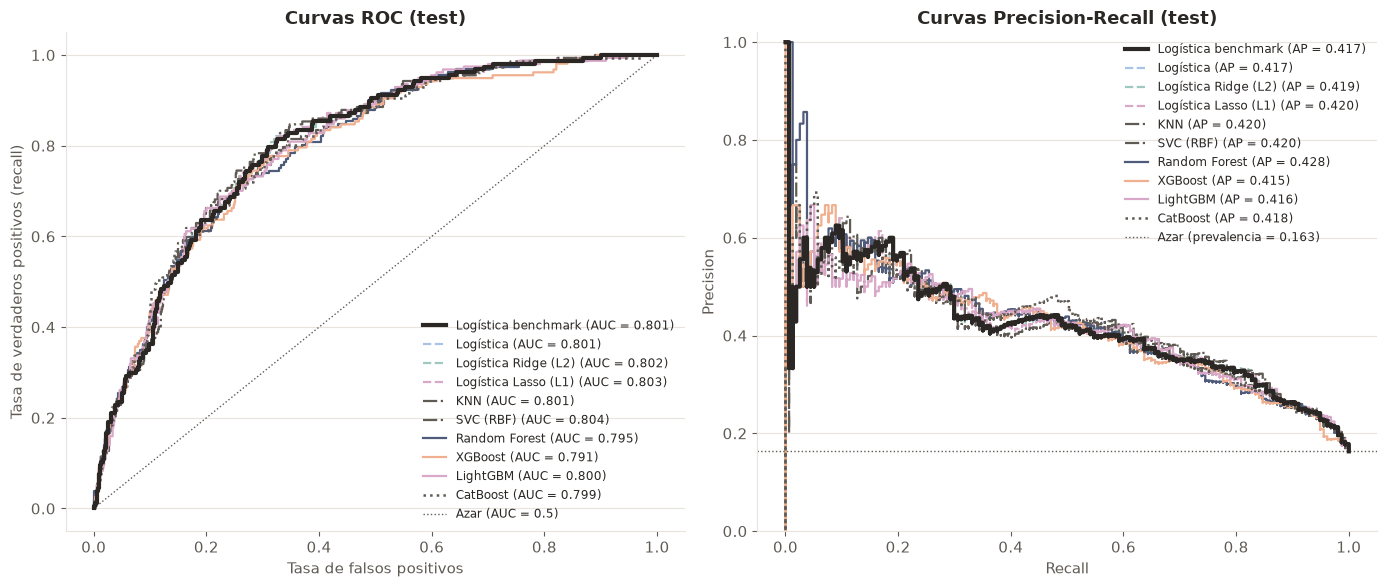

In [8]:
fig = graficar_curvas_test(probas_test, y_test)
plt.show()

**Intervalos bootstrap al 95%**

Con 962 adolescentes en el test (unos 157 deprimidos), la PR-AUC y la ROC-AUC tienen bastante variabilidad de muestreo. Para saber si las diferencias entre modelos son reales:

- **Réplicas:** se generan **1000 réplicas bootstrap** del test, remuestreando adolescentes con reemplazo.
- **Evaluación pareada:** en cada réplica se evalúan **todos los modelos sobre las mismas observaciones**.
- **Intervalos:** se obtiene el intervalo al 95% (percentiles 2.5 y 97.5) de la PR-AUC y la ROC-AUC de cada modelo, y también el de la **diferencia pareada frente al benchmark**.
- **Lectura:** si el intervalo de la diferencia **incluye el 0**, no hay evidencia de que el modelo sea distinto del benchmark. La columna `significativa` lo marca.

El intervalo de la diferencia es más informativo que comparar los intervalos individuales: como los modelos se evalúan sobre las mismas réplicas, buena parte de la variabilidad se cancela.

In [9]:
tabla_bootstrap = intervalos_bootstrap(y_test, probas_test, n_replicas=1000, seed=SEED)

columnas_pr = ["PR-AUC", "PR-AUC IC 2.5%", "PR-AUC IC 97.5%",
               "Δ PR-AUC vs benchmark", "Δ PR-AUC IC 2.5%", "Δ PR-AUC IC 97.5%", "Δ PR-AUC significativa"]
tabla_bootstrap[columnas_pr].rename(index=NOMBRES_FASE2).round(3)

,PR-AUC,PR-AUC IC 2.5%,PR-AUC IC 97.5%,Δ PR-AUC vs benchmark,Δ PR-AUC IC 2.5%,Δ PR-AUC IC 97.5%,Δ PR-AUC significativa
Modelo,,,,,,,
Random Forest,0.428,0.353,0.515,0.011,-0.026,0.045,False
KNN,0.420,0.348,0.505,0.003,-0.026,0.033,False
Logística Lasso (L1),0.420,0.348,0.511,0.002,-0.002,0.007,False
SVC (RBF),0.420,0.348,0.509,0.002,-0.006,0.010,False
Logística Ridge (L2),0.419,0.347,0.511,0.001,-0.000,0.003,False
CatBoost,0.418,0.345,0.506,0.000,-0.036,0.039,False
Logística,0.417,0.346,0.510,0.000,0.000,0.000,False
Logística benchmark,0.417,0.346,0.510,0.000,0.000,0.000,False
LightGBM,0.416,0.345,0.508,-0.001,-0.031,0.031,False


In [10]:
columnas_roc = ["ROC-AUC", "ROC-AUC IC 2.5%", "ROC-AUC IC 97.5%",
                "Δ ROC-AUC vs benchmark", "Δ ROC-AUC IC 2.5%", "Δ ROC-AUC IC 97.5%", "Δ ROC-AUC significativa"]
tabla_bootstrap[columnas_roc].rename(index=NOMBRES_FASE2).round(3)

,ROC-AUC,ROC-AUC IC 2.5%,ROC-AUC IC 97.5%,Δ ROC-AUC vs benchmark,Δ ROC-AUC IC 2.5%,Δ ROC-AUC IC 97.5%,Δ ROC-AUC significativa
Modelo,,,,,,,
Random Forest,0.795,0.756,0.831,-0.006,-0.017,0.005,False
KNN,0.801,0.763,0.835,-0.001,-0.011,0.008,False
Logística Lasso (L1),0.803,0.766,0.838,0.002,0.000,0.004,True
SVC (RBF),0.804,0.766,0.838,0.003,-0.003,0.008,False
Logística Ridge (L2),0.802,0.764,0.838,0.001,-0.000,0.002,False
CatBoost,0.799,0.760,0.834,-0.002,-0.013,0.006,False
Logística,0.801,0.763,0.837,0.000,0.000,0.000,False
Logística benchmark,0.801,0.763,0.837,0.000,0.000,0.000,False
LightGBM,0.800,0.760,0.833,-0.001,-0.011,0.008,False


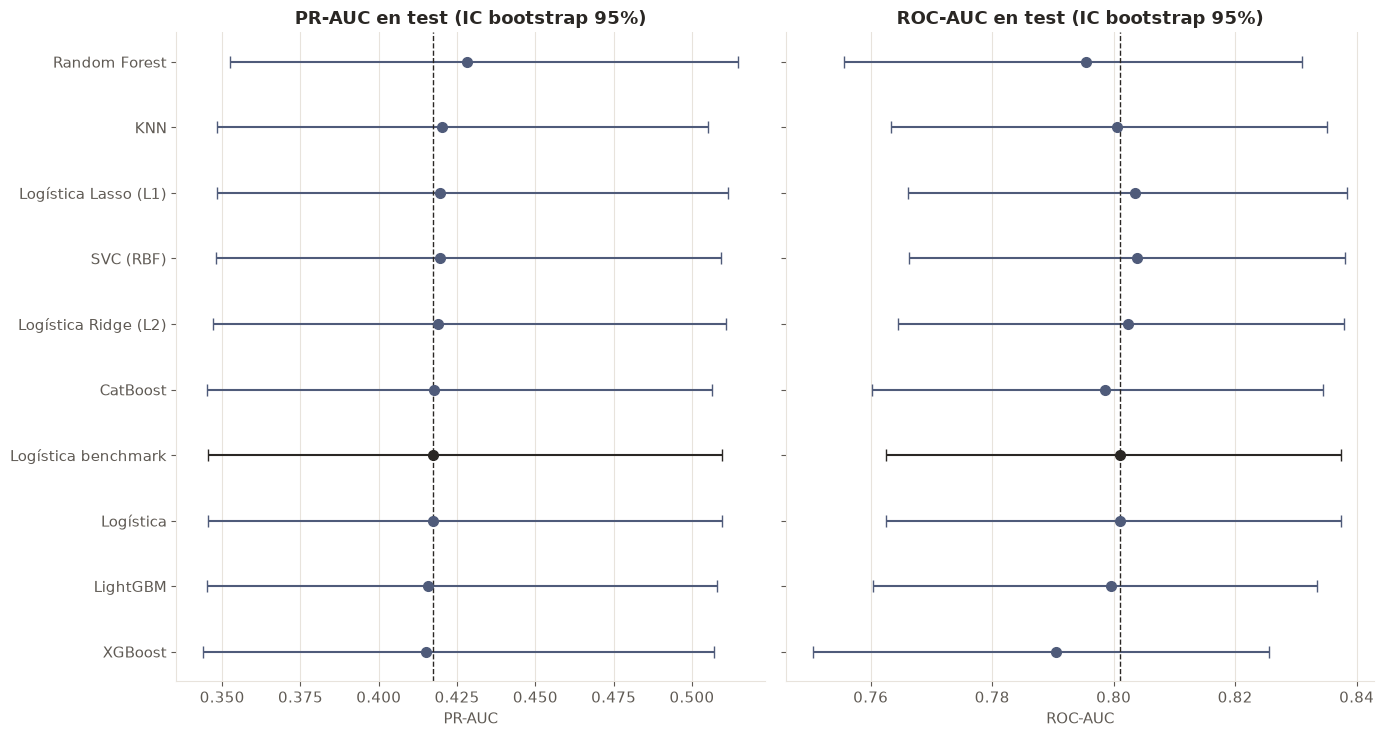

In [11]:
fig = graficar_intervalos_bootstrap(tabla_bootstrap)
plt.show()

## Optimización del Umbral

El umbral 0.5 no está optimizado, y su significado depende de la estrategia de balanceo de cada modelo. En esta fase se elige el umbral del modelo seleccionado **solo con el train**:

1. **Probabilidades:** se calculan probabilidades *out-of-fold* con `cross_val_predict` (mismos folds, `method="predict_proba"`). Cada adolescente del train recibe la probabilidad de un modelo que no lo vio al entrenar, así que son una estimación honesta de cómo se comporta el modelo con datos nuevos.
2. **Criterio principal (tamizaje):** la **mayor precision con recall ≥ 0.70**. Es decir, detectar al menos el 70% de los adolescentes deprimidos con la menor cantidad posible de falsas alarmas.
3. **Referencia:** el umbral que **maximiza el F1**.
4. **Test:** el umbral principal se aplica **una sola vez** al test y se compara con el umbral 0.5.

**El test nunca se usa para elegir el umbral.**

### Probabilidades Out-of-Fold

In [12]:
proba_oof = probabilidades_oof(pipelines[clave_mejor], clave_mejor, X_train, y_train, cv)

pd.Series({
    "Probabilidad media out-of-fold": round(proba_oof.mean(), 3),
    "Prevalencia (train)": round(y_train.mean(), 3),
}, name=NOMBRES_CLF[clave_mejor]).to_frame()

,CatBoost
Probabilidad media out-of-fold,0.164
Prevalencia (train),0.164


### Elección del Umbral

In [13]:
umbrales = elegir_umbrales(y_train, proba_oof, recall_minimo=RECALL_MINIMO)
pd.Series(umbrales, name="Valor").to_frame()

,Valor
umbral,0.15342
criterio,máxima precision con recall >= 0.70 (probabilidades out-of-fold del train)
precision_oof,0.294393
recall_oof,0.7
umbral_f1,0.199566
f1_oof,0.43452


In [14]:
# Métricas out-of-fold (train) con cada umbral
candidatos = {
    f"Umbral 0.5": UMBRAL,
    f"Umbral principal ({umbrales['umbral']:.3f})": umbrales["umbral"],
    f"Umbral máximo F1 ({umbrales['umbral_f1']:.3f})": umbrales["umbral_f1"],
}
pd.DataFrame({nombre: metricas_con_umbral(y_train, proba_oof, u) for nombre, u in candidatos.items()}).T.round(3)

,PR-AUC,ROC-AUC,Precision,Recall,F1,Accuracy
Umbral 0.5,0.392,0.75,0.572,0.132,0.214,0.842
Umbral principal (0.153),0.392,0.75,0.294,0.700,0.414,0.676
Umbral máximo F1 (0.200),0.392,0.75,0.351,0.571,0.435,0.756


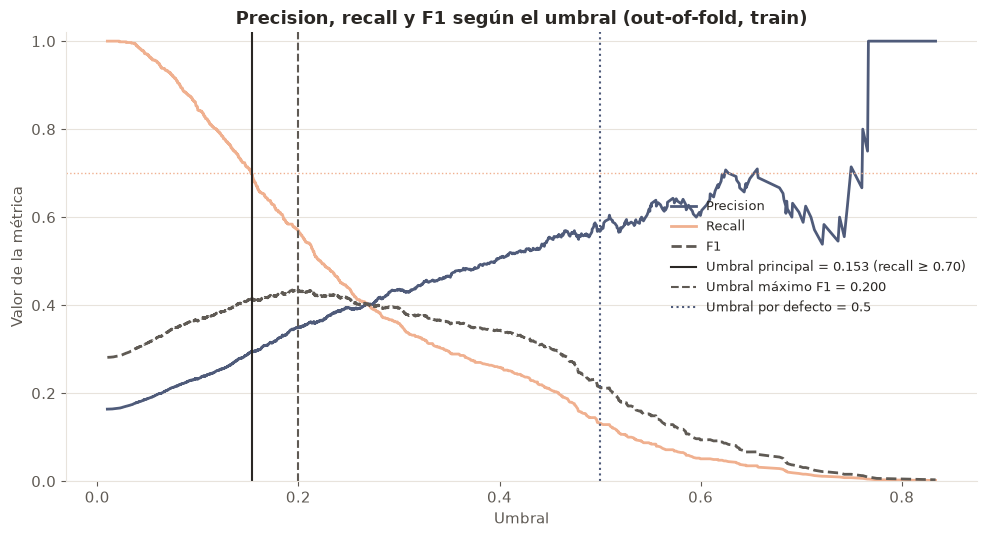

In [15]:
fig = graficar_umbral(y_train, proba_oof, umbrales)
plt.show()

### Aplicación al Test

El umbral principal, fijado con el train, se aplica **una sola vez** al test y se compara con el umbral 0.5. La PR-AUC y la ROC-AUC son iguales en ambas filas, porque no dependen del umbral.

In [16]:
proba_test_mejor = probas_test[clave_mejor]

metricas_test_final = pd.DataFrame({
    "Umbral 0.5": metricas_con_umbral(y_test, proba_test_mejor, UMBRAL),
    "Umbral elegido": metricas_con_umbral(y_test, proba_test_mejor, umbrales["umbral"]),
}).T
metricas_test_final.insert(0, "Umbral", [UMBRAL, umbrales["umbral"]])
metricas_test_final["Alertas (%)"] = [
    (proba_test_mejor >= UMBRAL).mean() * 100,
    (proba_test_mejor >= umbrales["umbral"]).mean() * 100,
]
metricas_test_final.index.name = NOMBRES_CLF[clave_mejor]
metricas_test_final.round(3)

,Umbral,PR-AUC,ROC-AUC,Precision,Recall,F1,Accuracy,Alertas (%)
CatBoost,,,,,,,,
Umbral 0.5,0.500,0.418,0.799,0.553,0.134,0.215,0.841,3.950
Umbral elegido,0.153,0.418,0.799,0.321,0.790,0.457,0.693,40.125


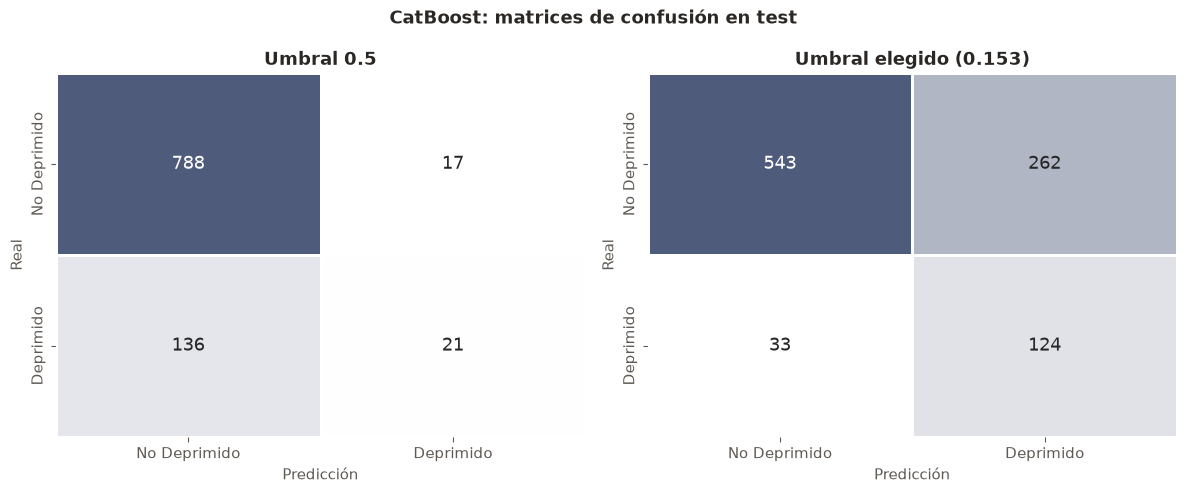

In [17]:
predicciones = {
    f"Umbral 0.5": (proba_test_mejor >= UMBRAL).astype(int),
    f"Umbral elegido ({umbrales['umbral']:.3f})": (proba_test_mejor >= umbrales["umbral"]).astype(int),
}
fig = graficar_matrices(y_test, predicciones, f"{NOMBRES_CLF[clave_mejor]}: matrices de confusión en test")
plt.show()

### Guardado del Modelo Final

In [20]:
metadatos = guardar_final(
    pipelines[clave_mejor], clave_mejor, ganadores[clave_mejor], umbrales, metricas_test_final, explicacion,
)

### Conclusiones